In [66]:
import pandas as pd
pd.set_option('display.max_rows',None)

In [2]:
pd.set_option('display.max_rows',10)

### UNIVARIATE ANALYSIS

In [3]:
#analsysis of 1 column-,then pandas profiling , them mulitvariate analaysis
#this will be useful to know what r the intresting features on our datset
import pandas as pd
pd.set_option('display.max_rows',None)

In [4]:
pd.set_option('display.max_rows',10)


### DATASET IMPORT

In [111]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [112]:
data = pd.read_csv("Dataset/gurgaon_properties_cleaned.csv")
data.head(3)

,property_name,property_type,society,sector,area,price,price_per_sqft,Plot area,Super Built Up area,Built Up area,...,TV,Microwave,Curtains,Washing Machine,Water Purifier,Wardrobe,Fan,Chimney,furnishing_type,luxury score
0,3 BHK Flat in Sector 81 Gurgaon,flat,DLF The Ultima,Sector 81 Gurgaon,2132.103,2.45,11491.0,0,0,0,...,0,0,1,1,0,3,8,1,2,183
1,2 BHK Flat in Sector 84 Gurgaon,flat,Antriksh Heights,Sector 84 Gurgaon,1529.878,0.85,5556.0,0,0,0,...,0,0,0,0,0,0,0,0,0,33
2,4 BHK Flat in Sector 72 Gurgaon,flat,Spaze Privy,Sector 72 Gurgaon,4632.397,3.10,6692.0,0,0,0,...,0,0,0,0,0,0,8,0,2,145


In [115]:
dt = data.copy()

In [106]:
dt.columns

Index(['property_name', 'property_type', 'society', 'sector', 'area', 'price',
       'price_per_sqft', 'Plot area', 'Super Built Up area', 'Built Up area',
       'Carpet area', 'bedRoom', 'bathroom', 'balcony', 'address', 'floorNum',
       'facing', 'agePossession', 'description', 'rating', 'Study Room',
       'Pooja Room', 'Servant Room', 'Store Room', 'Others', 'Light',
       'Modular Kitchen', 'Fridge', 'Dining Table', 'Bed', 'Exhaust Fan',
       'Stove', 'AC', 'Geyser', 'Sofa', 'TV', 'Microwave', 'Curtains',
       'Washing Machine', 'Water Purifier', 'Wardrobe', 'Fan', 'Chimney',
       'furnishing_type', 'luxury score'],
      dtype='object')

### property_type

In [8]:
dt['property_type'].value_counts()

property_type
flat     2708
house     985
Name: count, dtype: int64

<Axes: xlabel='property_type'>

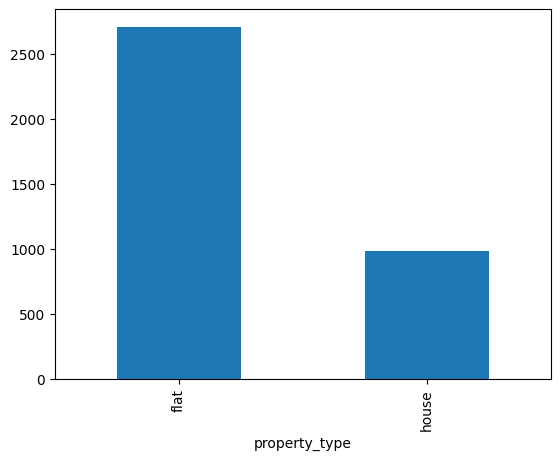

In [9]:
dt['property_type'].value_counts().plot(kind='bar',)

In [10]:
dt['property_type'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 3693 entries, 0 to 3692
Series name: property_type
Non-Null Count  Dtype 
--------------  ----- 
3693 non-null   object
dtypes: object(1)
memory usage: 29.0+ KB


In [11]:
dt['property_type'].value_counts()/3693

property_type
flat     0.733279
house    0.266721
Name: count, dtype: float64

###### Remarks:
1. This col contains 2 categories- [flat , house]  and no missing value
2. Majority of them are flats(73%) and (27%) houses.

### society

In [12]:
dt['society'].value_counts()

society
Tulip Violet                            75
SS The Leaf                             73
Shapoorji Pallonji Joyville Gurugram    44
DLF New Town Heights                    37
Shree Vardhman Victoria                 34
                                        ..
Antriksh Green                           1
 Near euro                               1
 Hsiidc Plot Sector 1 Imt Manesar        1
 Surat Nagar Phase 2                     1
 G block DLF City Phase 1                1
Name: count, Length: 863, dtype: int64

In [13]:
dt['society'].value_counts().sort_values(ascending=False).shape

(863,)

In [14]:
dt['society'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 3693 entries, 0 to 3692
Series name: society
Non-Null Count  Dtype 
--------------  ----- 
3693 non-null   object
dtypes: object(1)
memory usage: 29.0+ KB


In [15]:
dt['society'].value_counts().sort_values(ascending=False).head(100).cumsum()/(dt.shape[0])

society
Tulip Violet                            0.020309
SS The Leaf                             0.040076
Shapoorji Pallonji Joyville Gurugram    0.051990
DLF New Town Heights                    0.062009
Signature Global Park                   0.071216
                                          ...   
 Sector 56 Gurgaon                      0.500948
Unitech Espace                          0.503656
Unitech Uniworld Resorts                0.506363
Ansal Heights 86                        0.509071
DLF Regency Park                        0.511779
Name: count, Length: 100, dtype: float64

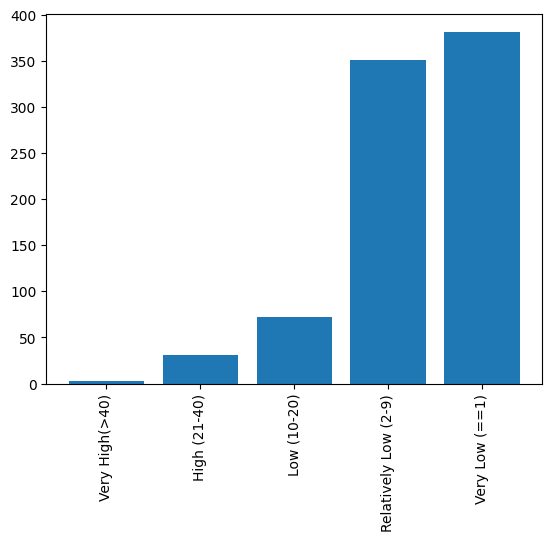

In [16]:
society_counts = dt['society'].value_counts()
freq_bins = {
    "Very High(>40)": (society_counts>40).sum(),
    "High (21-40)": ((society_counts>=21) & (society_counts<=50)).sum(),
    "Low (10-20)": ((society_counts>=10) & (society_counts<=20)).sum(),
    "Relatively Low (2-9)":((society_counts>=2) & (society_counts<=7)).sum(),
    'Very Low (==1)':(society_counts==1).sum()
    
}
freq_bins
plt.bar(freq_bins.keys(),freq_bins.values(),linewidth=0.9)
plt.xticks(rotation='vertical')
plt.show()

In [17]:
freq_bins.keys(), freq_bins.values()

(dict_keys(['Very High(>40)', 'High (21-40)', 'Low (10-20)', 'Relatively Low (2-9)', 'Very Low (==1)']),
 dict_values([np.int64(3), np.int64(31), np.int64(72), np.int64(351), np.int64(382)]))

In [18]:
dt['society'].isnull().sum()

np.int64(0)

##### Remarks:
1. wide variety of categories
2. No missing value
3. out of 863 different values 100 different societies contain 50% of whole data
4. only 3 societies has 40+ properties to sell, 31 societies has 21-40 properties,72 societies has 10-20 properties,351 has 2-9 properties and 382 has 1 properties.

### sector

In [19]:
dt['sector'].value_counts()

sector
Sohna                   140
Sector 102 Gurgaon      111
Sector 85 Gurgaon       107
Sector 109 Gurgaon      100
Sector 69 Gurgaon        92
                       ... 
Alipur                    1
Golf Course Ext Road      1
New Colony, Sector 7      1
Sector-2 Sohna            1
Shanti Nagar              1
Name: count, Length: 294, dtype: int64

In [20]:
sector_counts = dt['sector'].value_counts()

sector_freq_bins = {
    "Very High (>100)": (sector_counts > 100).sum(),
    "High (50-100)": ((sector_counts >= 50) & (sector_counts <= 100)).sum(),
    "Average (10-49)": ((sector_counts >= 10) & (sector_counts < 50)).sum(),
    "Low (2-9)": ((sector_counts > 1) & (sector_counts < 10)).sum(),
    "Very Low (1)": (sector_counts == 1).sum()
}

sector_freq_bins

{'Very High (>100)': np.int64(3),
 'High (50-100)': np.int64(20),
 'Average (10-49)': np.int64(63),
 'Low (2-9)': np.int64(129),
 'Very Low (1)': np.int64(79)}

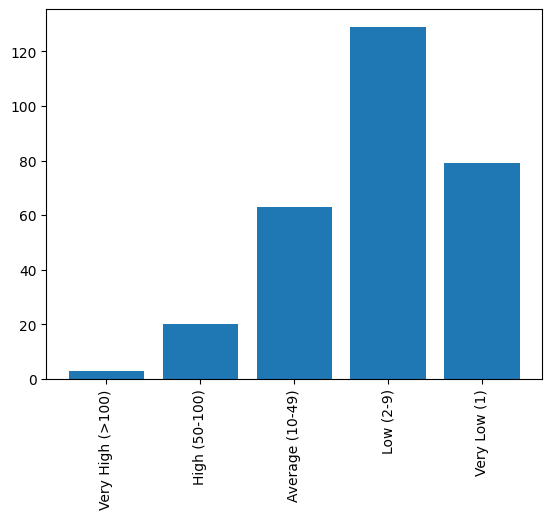

In [21]:
plt.bar(sector_freq_bins.keys(),sector_freq_bins.values(),linewidth=0.9)
plt.xticks(rotation='vertical')
plt.show()

##### Remarks:
1. No missing value
2. Very High (>100): 3 sectors have more than 100 listings.
3. High (50-100): 20 sectors have between 50 to 100 listings.
4. Average (10-49): A majority, 633 sectors, fall in this range with 10 to 49 listings each.
5. Low (2-9): 129 sectors have between 2 to 9 listings.
6. Very Low (1): 79 sectores has 1 listing.

### price

In [22]:
dt['price'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 3693 entries, 0 to 3692
Series name: price
Non-Null Count  Dtype  
--------------  -----  
3693 non-null   float64
dtypes: float64(1)
memory usage: 29.0 KB


In [23]:
dt['price'].value_counts()

price
1.250    77
1.100    66
0.900    61
1.400    61
1.200    58
         ..
7.600     1
8.310     1
2.690     1
3.003     1
8.600     1
Name: count, Length: 582, dtype: int64

In [24]:
#Quantiles calculation
dt['price'].quantile([0.01,0.10,0.55,0.90])

0.01    0.2500
0.10    0.5252
0.55    1.7300
0.90    6.0980
Name: price, dtype: float64

<BarContainer object of 582 artists>

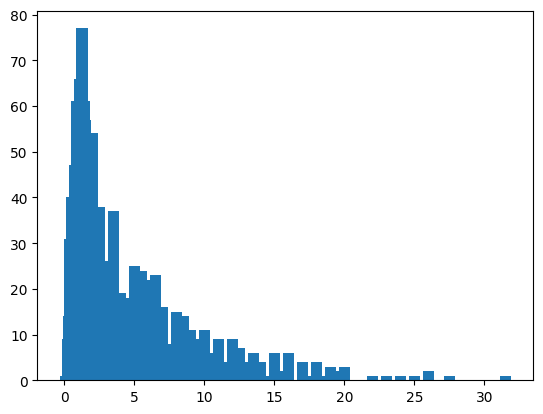

In [25]:
plt.bar(dt['price'].value_counts().index,dt['price'].value_counts().values)

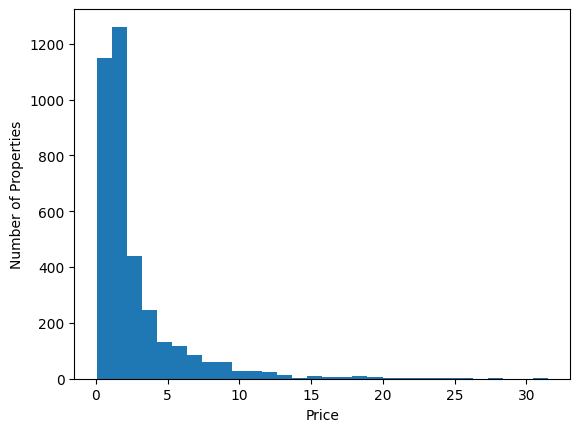

In [26]:
plt.hist(data['price'], bins=30)
plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.show()

In [27]:
#skewness and kurtosis
dt['price'].skew(),dt['price'].kurtosis()

(np.float64(3.150256737779831), np.float64(13.813433167095681))

In [28]:
#log transformation

In [29]:
dt['price'].describe()

count    3693.000000
mean        2.620542
std         3.029787
min         0.075000
25%         0.950000
50%         1.590000
75%         2.950000
max        31.500000
Name: price, dtype: float64

In [30]:
#outlier detection
q1 = dt['price'].describe()['25%']
q3 = dt['price'].describe()['75%']
iqr = q3-q1
l_bound = q1-1.5*iqr
u_bound = q3+1.5*iqr
print(q1,q3,iqr,l_bound,u_bound)

0.95 2.95 2.0 -2.05 5.95


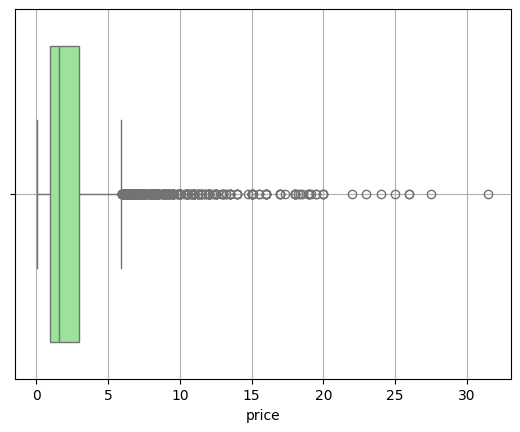

In [31]:
sns.boxplot(x=dt['price'],color='lightgreen')
plt.grid()

In [32]:
outliers = dt[(dt['price']<l_bound) | (dt['price']>u_bound)]
outliers.shape

(394, 25)

In [33]:
outliers['price'].describe()

count    394.000000
mean       9.755810
std        4.035179
min        6.000000
25%        6.950000
50%        8.500000
75%       11.000000
max       31.500000
Name: price, dtype: float64

In [34]:
q1 = outliers['price'].describe()['25%']
q3 = outliers['price'].describe()['75%']
iqr = q3-q1
l_bound = q1-1.5*iqr
u_bound = q3+1.5*iqr
print(q1,q3,iqr,l_bound,u_bound)

6.95 11.0 4.05 0.8750000000000009 17.075


In [35]:
print("before transofrmation :" ,outliers['price'].skew(),outliers['price'].kurtosis())
print("After transofrmation :" ,np.log(outliers['price']).skew(),np.log(outliers['price']).kurtosis())


before transofrmation : 1.9477443102560057 4.672732447361395
After transofrmation : 0.9690730956773876 0.4755012806943384


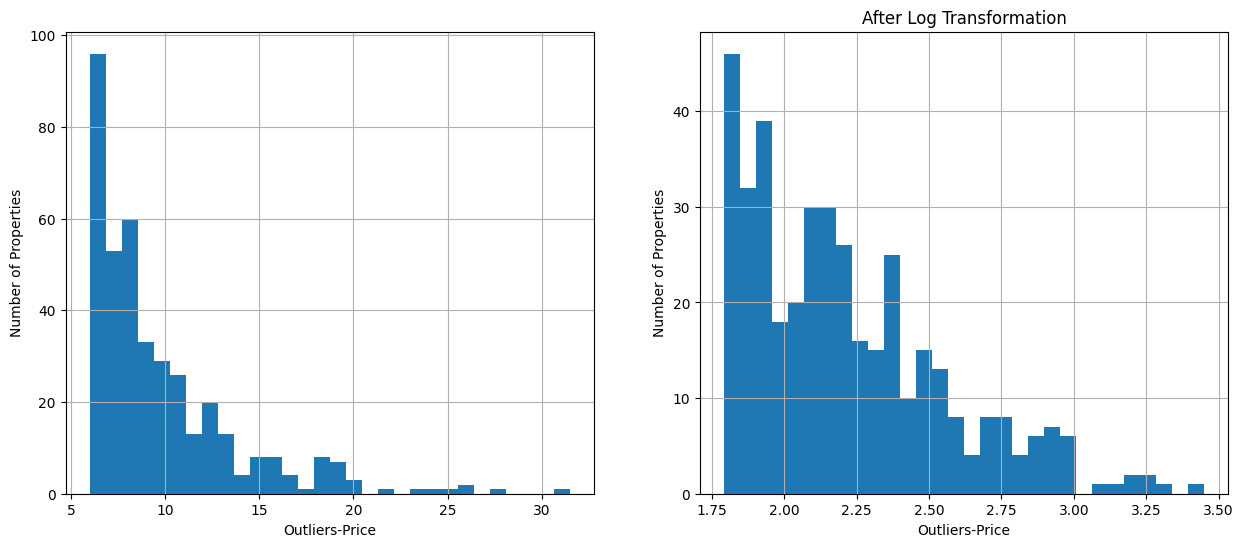

In [36]:
#transformation
plt.figure(figsize=(15, 6))
plt.subplot(1,2,1)
plt.hist(outliers['price'], bins=30)
plt.xlabel("Outliers-Price")
plt.ylabel("Number of Properties")
plt.grid()

plt.subplot(1,2,2)
plt.hist(np.log(outliers['price']), bins=30)
plt.title("After Log Transformation")
plt.xlabel("Outliers-Price")
plt.ylabel("Number of Properties")
plt.grid()
plt.show()

np.log1p(x): This function computes the natural logarithm of 1+x. It's designed to provide more accurate results for values of x that are very close to zero.

Using np.log1p helps in transforming the price column while ensuring that any value (including zero, if present) is handled appropriately. When we need to reverse the transformation, we can use np.expm1 which computes e^x-1

In [37]:
updated_price = np.log(dt['price'])
reci_price = np.reciprocal(dt['price'])
from scipy.stats import boxcox
boxcox_price,lambda_value = boxcox(dt['price'])
boxcox_price,lambda_value

from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='yeo-johnson',standardize=False)
k = pt.fit_transform(dt[['price']])


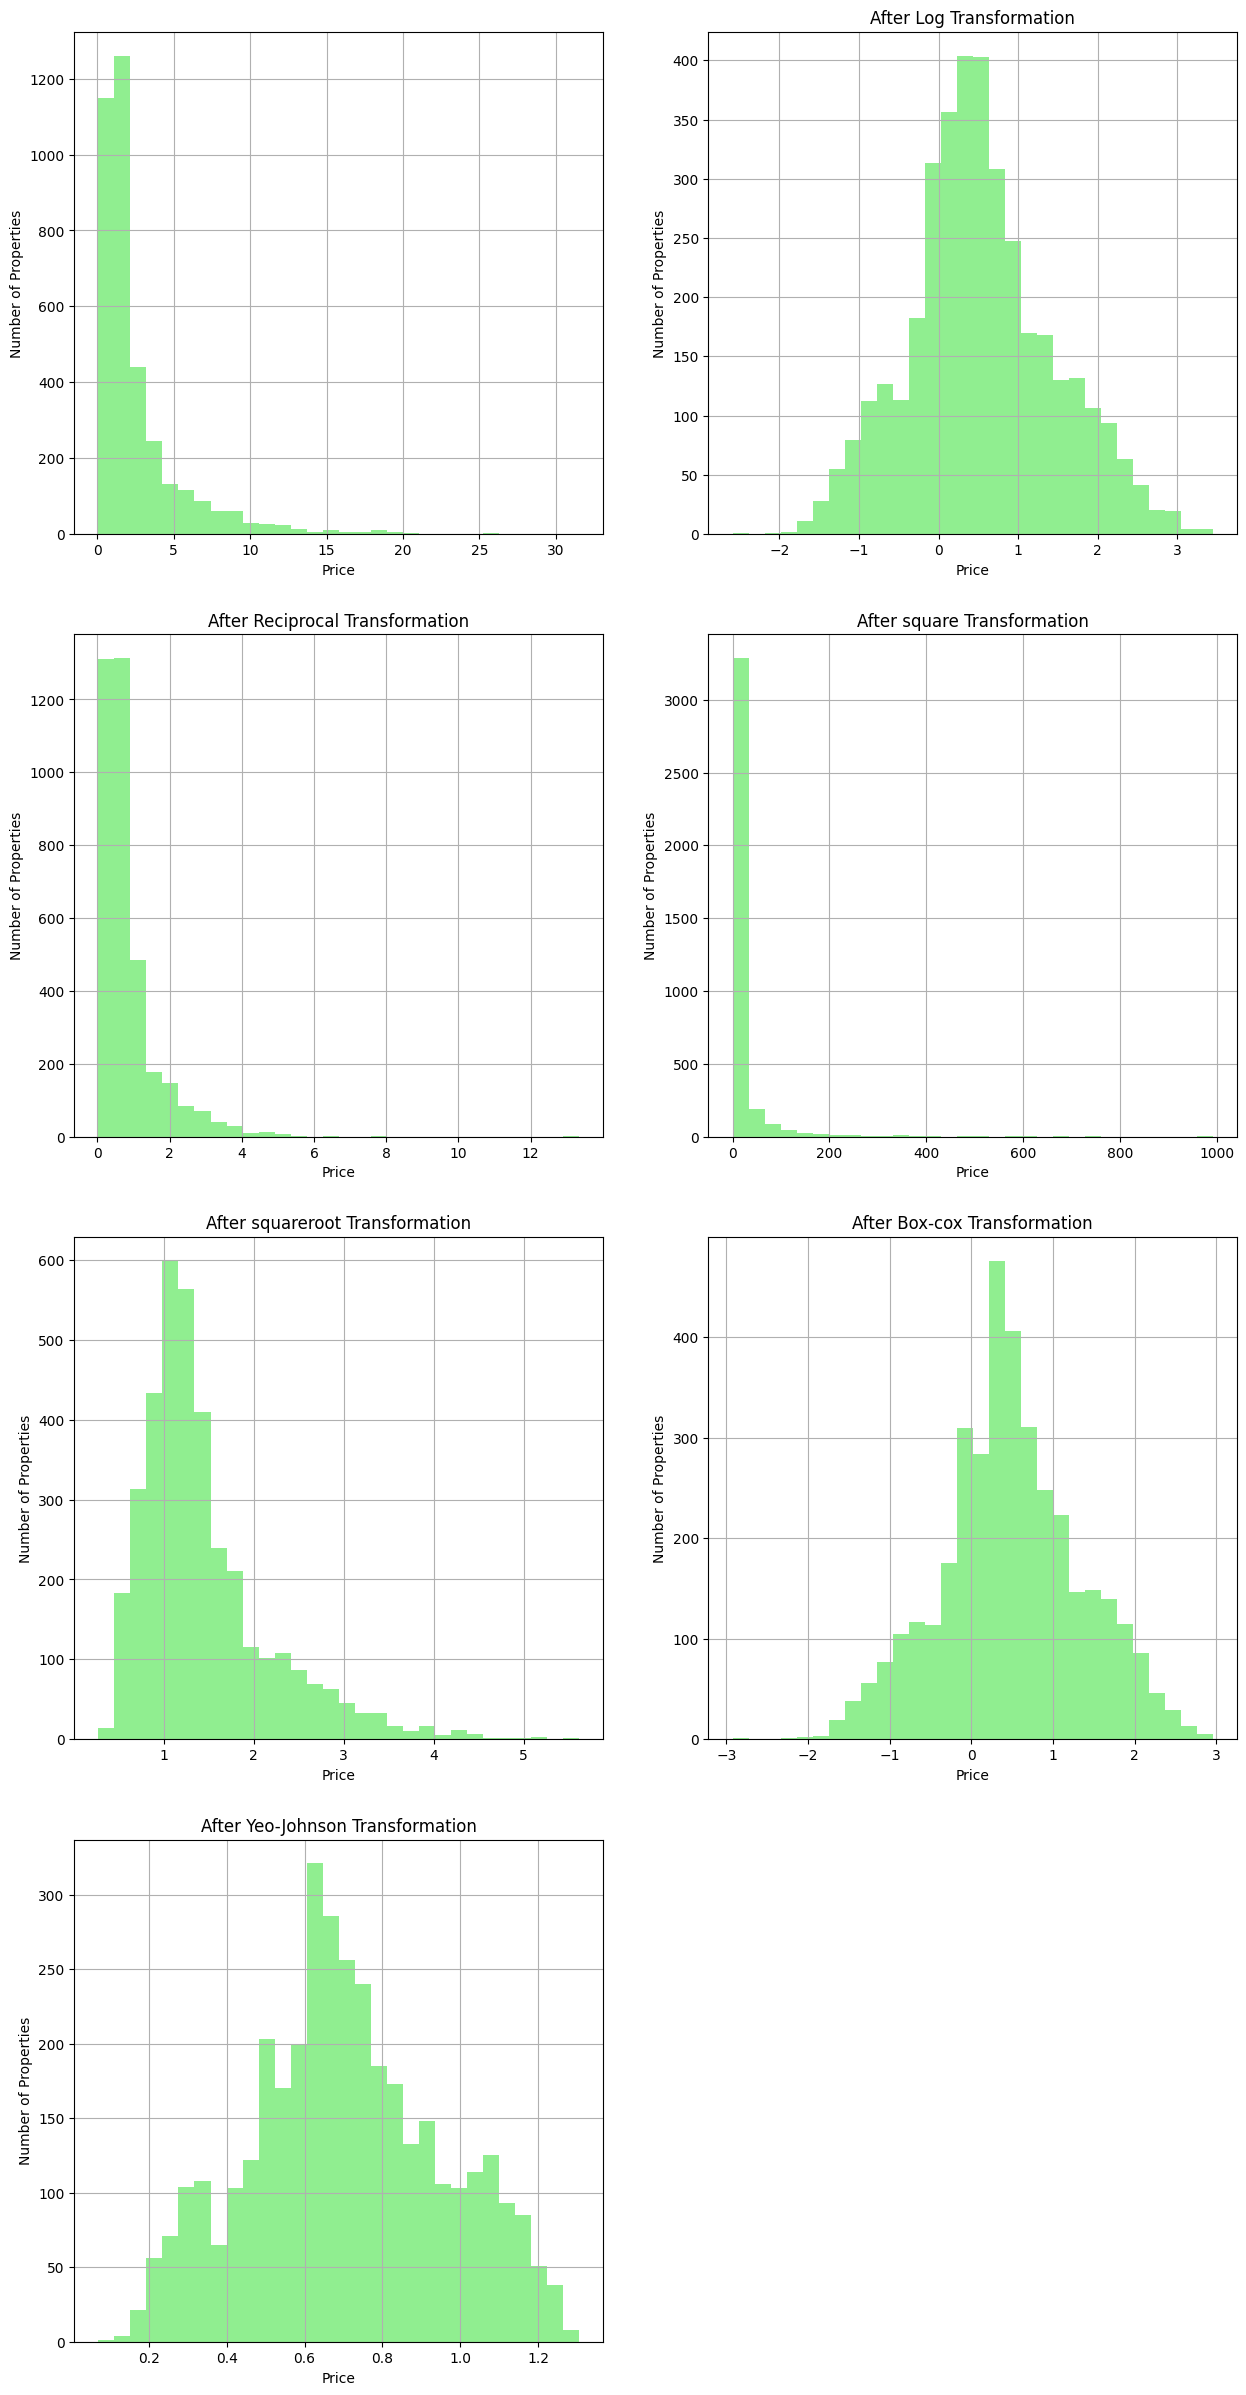

In [38]:
#transformation
plt.figure(figsize=(15, 30))
plt.subplot(4,2,1)
plt.hist(dt['price'], bins=30,color='lightgreen')
plt.xlabel("Price")
plt.grid()
plt.ylabel("Number of Properties")

plt.subplot(4,2,2)
plt.hist(updated_price, bins=30,color='lightgreen')
plt.title("After Log Transformation")
plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.grid()


plt.subplot(4,2,3)
plt.hist(reci_price, bins=30,color='lightgreen')
plt.title("After Reciprocal Transformation")
plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.grid()

plt.subplot(4,2,4)
plt.hist(np.square(dt['price']), bins=30,color='lightgreen')
plt.title("After square Transformation")
plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.grid()


plt.subplot(4,2,5)
plt.hist(np.sqrt(dt['price']), bins=30,color='lightgreen')
plt.title("After squareroot Transformation")
plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.grid()

plt.subplot(4,2,6)
plt.hist(boxcox_price, bins=30,color='lightgreen')
plt.title("After Box-cox Transformation")
plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.grid()

plt.subplot(4,2,7)
plt.hist(k, bins=30,color='lightgreen')
plt.title("After Yeo-Johnson Transformation")
plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.grid()
plt.show()
 # log transformation performs best

In [39]:
print("before transofrmation :" ,dt['price'].skew(),dt['price'].kurtosis())
print("After transofrmation :" ,np.log(dt['price']).skew(),np.log(dt['price']).kurtosis())

before transofrmation : 3.150256737779831 13.813433167095681
After transofrmation : 0.2419162200254284 -0.018581792205908165


**Skewness** measures the asymmetry of a probability distribution around its mean. It indicates whether data values are stretched more toward the left or the right side, affecting the distribution’s overall balance.

Helps understand the direction of extreme values.
Influences the difference between mean, median and mode.
Useful in identifying required transformations for modelling.

**Kurtosis** measures how sharp the peak of a distribution is and how heavy or light its tails are compared to a normal distribution. It shows how much of the data lies close to the center and how much appears in the extreme ends.

Higher kurtosis implies more extreme outliers.
Lower kurtosis implies fewer extreme values and smoother tails.
Excess kurtosis (kurtosis − 3) is commonly used for interpretation.

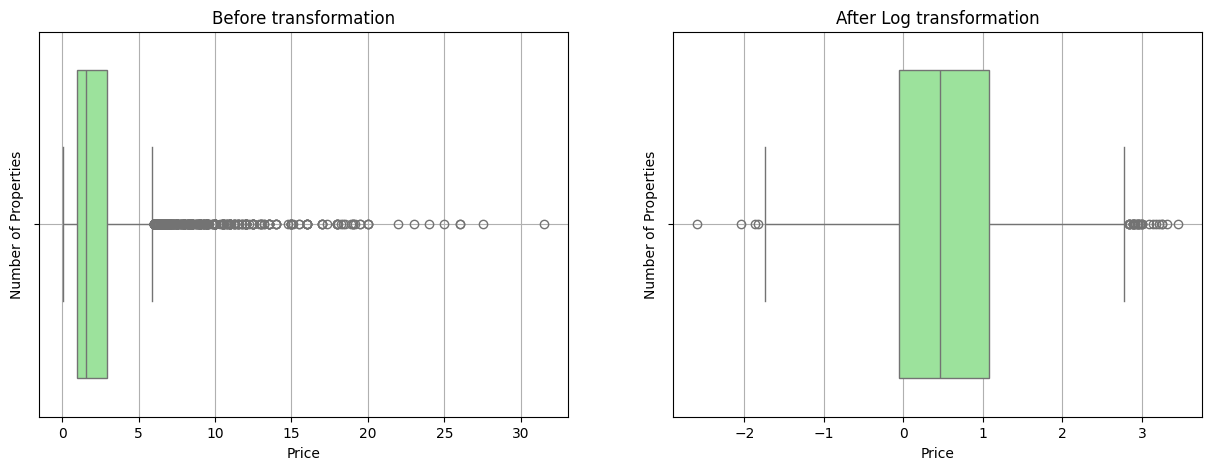

In [40]:
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
sns.boxplot(x=dt['price'],color='lightgreen')
plt.title("Before transformation")
plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.grid()


plt.subplot(1,2,2)
sns.boxplot(x=updated_price,color='lightgreen')
plt.title("After Log transformation")
plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.grid()
plt.show()

In [41]:
q1 = updated_price.quantile(0.25)
q3 = updated_price.quantile(0.75)
iqr = q3-q1
l_bound = q1-1.5*iqr
u_bound = q3+1.5*iqr
outliers = (updated_price<l_bound) | (updated_price>u_bound)
print(q1,q3,iqr,l_bound,u_bound)

-0.05129329438755058 1.0818051703517284 1.133098464739279 -1.750940991496469 2.781452867460647


In [42]:
outliers.sum()

np.int64(35)

<Axes: xlabel='price'>

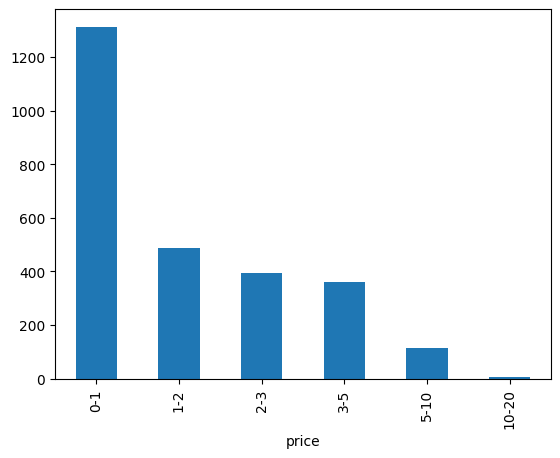

In [43]:
bins = [1,2,3,5,10,20,30]
bin_labels = ['0-1','1-2','2-3','3-5','5-10','10-20']
pd.cut(dt['price'] , bins=bins,labels=bin_labels).value_counts().plot(kind='bar')

1. Majority of properties is in under 1 crore.
2. There is significant drop in under 5 and then above 5


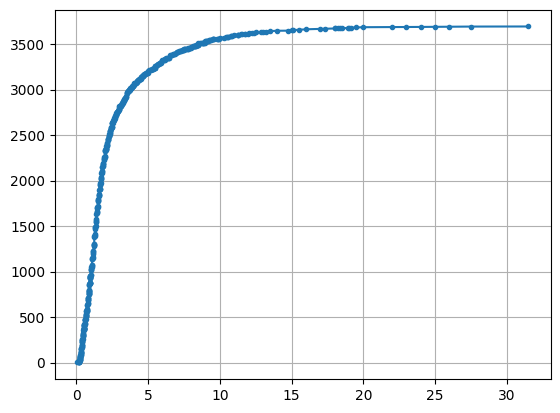

In [44]:
#An ECDF plot (Empirical Cumulative Distribution Function) 
#shows what percentage of your data values are less than or equal to a particular value.
ecdf = dt['price'].value_counts().sort_index().cumsum()/len(dt['price'].shape)
plt.plot(ecdf.index,ecdf,linestyle=None,marker='.')
plt.grid()

##### Remarks:
1. No missing value
2. min value of price- 7.5 lac , max-31.5 crore , mean -2..62 crore ,median-1.59 crore,25%-95 lac,75%-2.95 crore - the data is right skewed
3. outliers-394 elements:
       1. outlier data is  right skewed.
       2. after log transformation - found only 35 outliers
5. Visualization-
        1. price col is right skewed with skew=3.15 kurtosis=13.15
        2. out of many transformations-log tranformation works best to make the distribution of data normal
        3. Log transformation gives least number of outliers
   

### price_per_sqft

In [45]:
dt['price_per_sqft'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 3693 entries, 0 to 3692
Series name: price_per_sqft
Non-Null Count  Dtype  
--------------  -----  
3693 non-null   float64
dtypes: float64(1)
memory usage: 29.0 KB


In [46]:
dt['price_per_sqft'].value_counts()

price_per_sqft
10000.0    27
8000.0     19
12500.0    16
5000.0     16
22222.0    15
           ..
14603.0     1
9868.0      1
3560.0      1
8998.0      1
15240.0     1
Name: count, Length: 2587, dtype: int64

In [47]:
dt['price_per_sqft'].describe()

count      3693.000000
mean      14399.666667
std       23864.351185
min           2.000000
25%        7036.000000
50%        9259.000000
75%       14100.000000
max      600000.000000
Name: price_per_sqft, dtype: float64

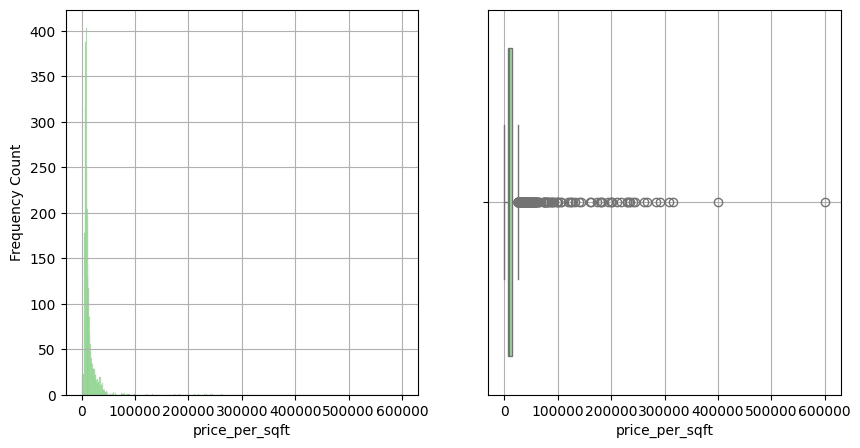

In [48]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.histplot(dt['price_per_sqft'] ,color='lightgreen')
plt.xlabel('price_per_sqft')
plt.ylabel('Frequency Count')
plt.grid()

plt.subplot(1,2,2)
sns.boxplot(x=dt['price_per_sqft'],color='lightgreen')
plt.xlabel('price_per_sqft')
plt.grid()
plt.show()

In [49]:
dt['price_per_sqft'].quantile(0.75)

np.float64(14100.0)

In [50]:
dt['price_per_sqft'].isnull().sum()

np.int64(0)

In [51]:
q1 = dt['price_per_sqft'].quantile(0.25)
q3 = dt['price_per_sqft'].quantile(0.75)
iqr = q1-q3
lower_bound = q1-1.5*iqr
upper_bound = q3+1.5*iqr
cleaned = dt[(dt['price_per_sqft']<lower_bound) & (dt['price_per_sqft']>upper_bound)]

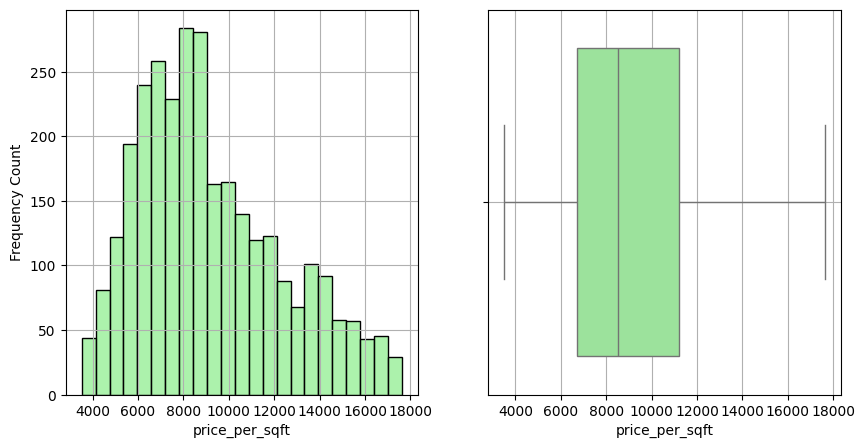

In [52]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.histplot(cleaned['price_per_sqft'] ,color='lightgreen')
plt.xlabel('price_per_sqft')
plt.ylabel('Frequency Count')
plt.grid()

plt.subplot(1,2,2)
sns.boxplot(x=cleaned['price_per_sqft'],color='lightgreen')
plt.xlabel('price_per_sqft')
plt.grid()
plt.show()

In [53]:
cleaned['price_per_sqft'].describe()

count     3025.000000
mean      9186.992397
std       3181.720858
min       3516.000000
25%       6724.000000
50%       8518.000000
75%      11204.000000
max      17624.000000
Name: price_per_sqft, dtype: float64

In [54]:
cleaned['price_per_sqft'].skew(),cleaned['price_per_sqft'].kurtosis()
#skewness tells about symmetry - 0.5<symmetric , else asymmetric ,negative-left skewed, pos-right skewed
#kurtosis tells extremity not peak height - raw kurtosis-3,excess kurtosis-0

(np.float64(0.6384932157145864), np.float64(-0.3314811019561854))

###### Remarks:
1. No missing values
2. The distribution contain huge amount of outliers.
3. After removing outliers - normal distribution can be achieved
4. after removal-> min:3516,max:17624,25%:6724,median:8518,75%:11204.
   

### bedRoom

In [55]:
dt['bedRoom'].value_counts() , dt['bedRoom'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 3693 entries, 0 to 3692
Series name: bedRoom
Non-Null Count  Dtype
--------------  -----
3693 non-null   int64
dtypes: int64(1)
memory usage: 29.0 KB


(bedRoom
 3     1489
 2      902
 4      693
 5      224
 1      119
       ... 
 14       1
 21       1
 20       1
 34       1
 36       1
 Name: count, Length: 21, dtype: int64,
 None)

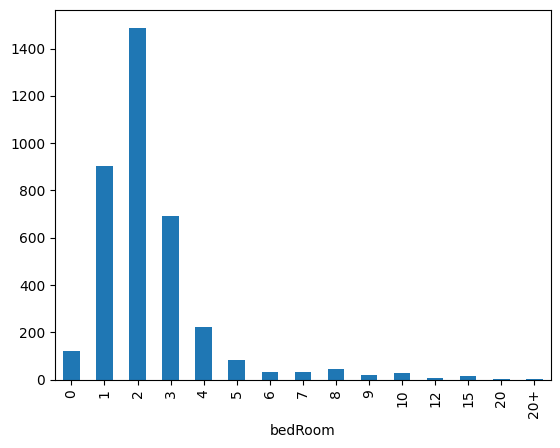

In [56]:
bins=[0,1,2,3,4,5,6,7,8,9,10,12,15,20,30,35]
bins_labels=['0','1','2','3','4','5','6','7','8','9','10','12','15','20','20+']
pd.cut(dt['bedRoom'],bins=bins,labels=bins_labels).value_counts().sort_index().plot(kind='bar')
plt.show()


In [57]:
dt['bedRoom'].quantile(0.99)

np.float64(12.0)

In [58]:
p = dt[dt['bedRoom']<20]['bedRoom']

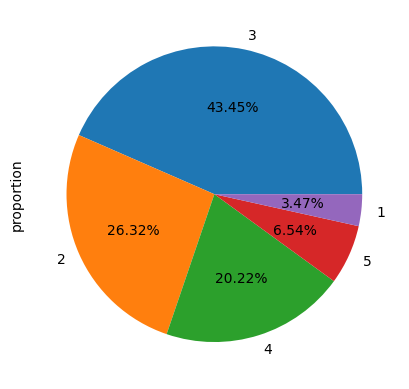

In [59]:
p.value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')
plt.show()

##### Remarks:
1. max properties are of 2BHk,then 1BHK,3BHK, and only few of them has 10+ bedRooms
2. no missing values

### balcony

In [60]:
dt['balcony'].value_counts()

balcony
3+               1156
3                1060
2                 883
1                 364
No                190
Not Avaliable      40
Name: count, dtype: int64

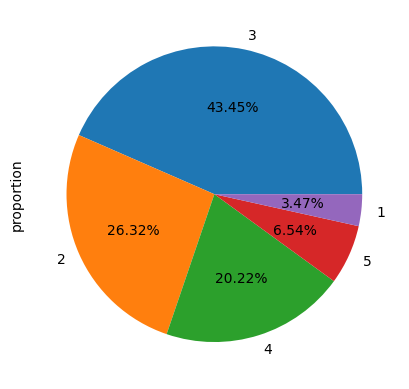

In [61]:
p.value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')
plt.show()

##### Remarks:
1. no missing values
2. around 43.45% properties has 3 balcony , 26% has 2 balcony, 20% has 4 balcony , and small percentages has 1 and 5 balcony

### floorNum

In [67]:
dt['floorNum'].value_counts()


floorNum
3                521
2                517
1                379
4                328
8                183
10               178
6                175
7                173
5                169
9                156
12               155
14               145
11               101
15                82
Not Avaliable     59
16                51
17                46
18                41
13                40
19                37
20                26
21                20
23                14
24                12
22                11
25                10
27                 8
26                 8
0                  6
28                 5
30                 5
33                 4
31                 4
40                 3
29                 3
51                 3
43                 2
39                 2
35                 2
34                 2
32                 2
45                 1
38                 1
41                 1
44                 1
02                 1
Name: count, dtype: int64

In [81]:
k = dt[dt['floorNum']!='Not Avaliable']['floorNum']
k = k.astype('int')


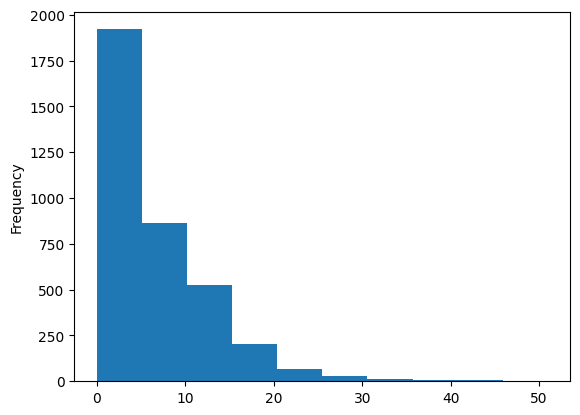

In [82]:
k.plot(kind='hist')
plt.show()

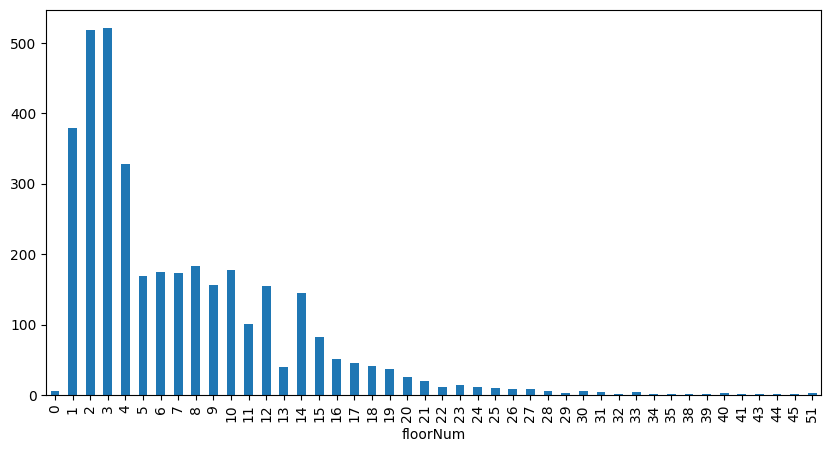

In [88]:
plt.figure(figsize=(10,5))
k.value_counts().sort_index().plot(kind='bar')
plt.show()

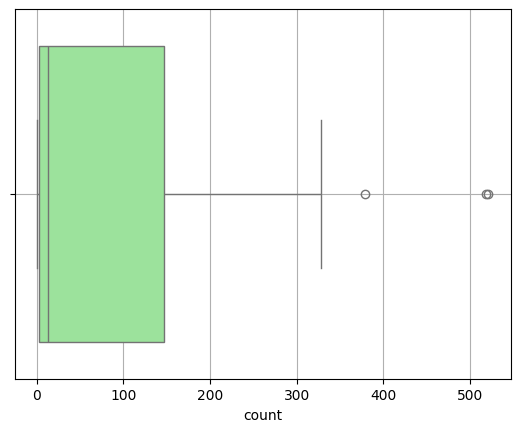

In [95]:
sns.boxplot(x=k.value_counts().sort_index(),color='lightgreen')
plt.grid()
plt.show()

##### Remarks:
1. No missing value
2. max 0-5 floorNum
3. all values almost lies between 0-25th floor
4. max frequent floorNum are 3
5. majority of floors lie between 1-25
6. iqr = max to max between 2-12

### facing

In [98]:
 k = dt[dt['facing']!='Not Avaliable']['facing']
k.value_counts()

facing
North-East    635
East          618
North         387
West          249
South         233
North-West    203
South-East    177
South-West    157
Name: count, dtype: int64

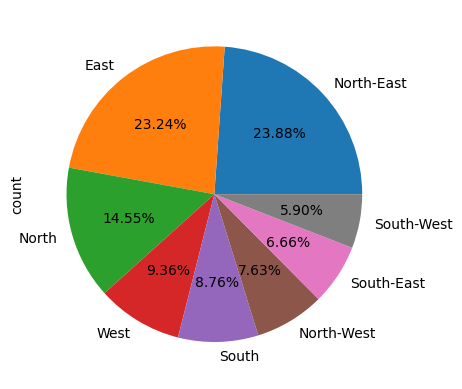

In [100]:
k.value_counts().plot(kind='pie',autopct='%0.2f%%')
plt.show()

##### Remarks:
1. 23.88%  are in north-east direction
2. 23.24% are in east direction
3. 14.55% are facing in north direction
4. 9.36% are facing in west and rest of them are in other directions

### additionalRoom - servant room,pooja room,others,store room,study room 

In [120]:
dis = ['Study Room', 'Pooja Room', 'Servant Room', 'Store Room', 'Others']
for i in dis:
    print(dt[i].value_counts().sort_index())

    

Study Room
0    2999
1     694
Name: count, dtype: int64
Pooja Room
0    3022
1     671
Name: count, dtype: int64
Servant Room
0    2364
1    1329
Name: count, dtype: int64
Store Room
0    3340
1     353
Name: count, dtype: int64
Others
0    3296
1     397
Name: count, dtype: int64


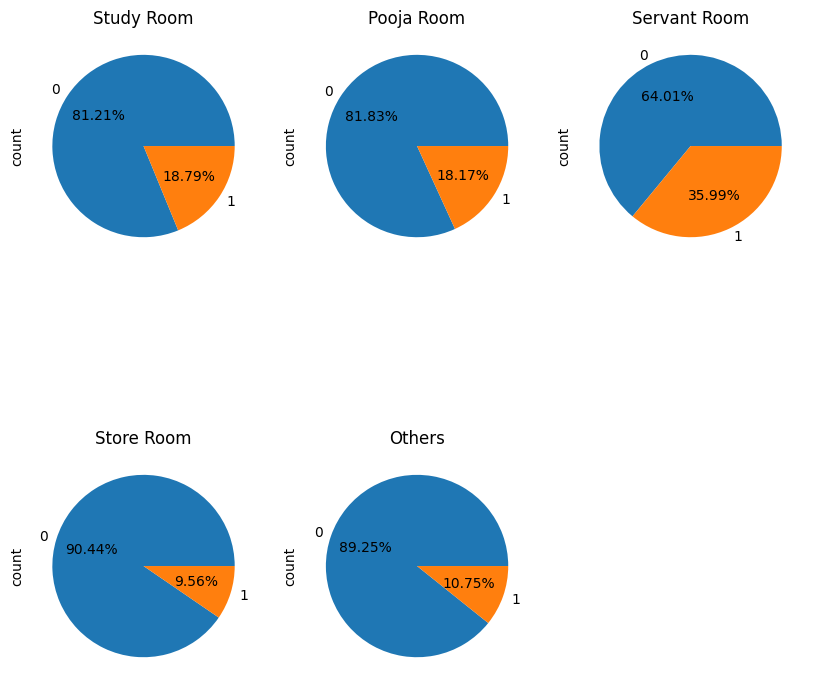

In [127]:
dis = ['Study Room', 'Pooja Room', 'Servant Room', 'Store Room', 'Others']
p=1
plt.figure(figsize=(10,10))
for i in dis:
    plt.subplot(2,3,p)
    dt[i].value_counts().plot(kind='pie',autopct='%0.2f%%')
    plt.title(i)
    p+=1
plt.show()
    

##### Remarks:
1. only 18% room has Study room,Pooja room
2. around 40% room has Servant room
3. only 9.5% has Store room and other rooms


### furnishing_type

In [128]:
dt['furnishing_type'].value_counts()

furnishing_type
0    2447
2    1042
1     204
Name: count, dtype: int64

<Axes: ylabel='count'>

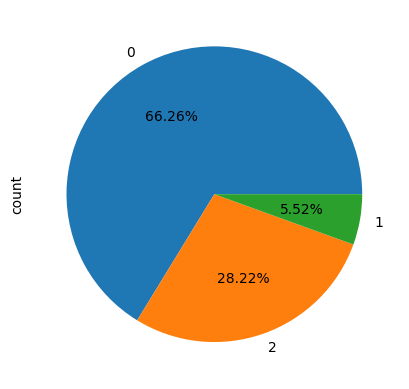

In [130]:
dt['furnishing_type'].value_counts().plot(kind='pie',autopct='%0.2f%%')
#0->unfurnished
#1->semi furnished
#2->furnished

### luxury_score

In [134]:
k = dt['luxury score'].value_counts().sort_index()

In [136]:
k.describe()

count    170.000000
mean      21.723529
std       58.410403
min        1.000000
25%        7.000000
50%       12.000000
75%       19.000000
max      670.000000
Name: count, dtype: float64

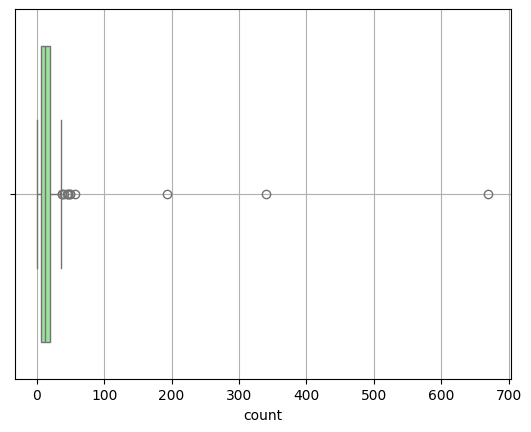

In [139]:
sns.boxplot(x=k,color='lightgreen')
plt.grid()
plt.show()

<Axes: xlabel='luxury score', ylabel='Count'>

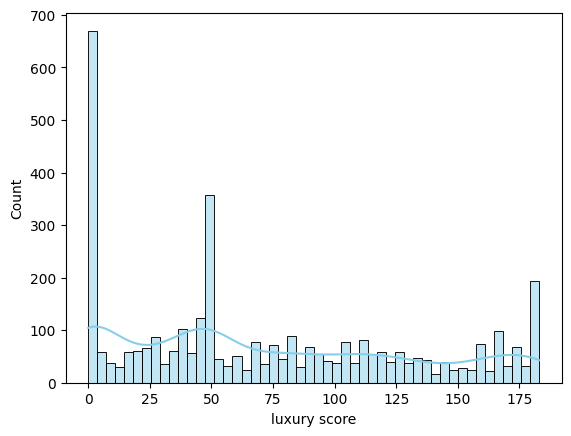

In [144]:
sns.histplot(dt['luxury score'], bins=50, color='skyblue', kde=True)

In [162]:
#removing outlier
q1 = dt['luxury score'].quantile(0.25)
q3 = dt['luxury score'].quantile(0.75)
iqr = q3-q1
l_bound = q1-1.5*iqr
u_bound = q3+1.5*iqr
k = dt[(dt['luxury score']<l_bound) | (dt['luxury score']>u_bound)]['luxury score']


In [164]:
k

Series([], Name: luxury score, dtype: int64)

##### Remarks:
The luxury score distribution has multiple peaks, suggesting a multi-modal distribution. There's a significant number of properties with lower luxury scores (around 0-50), and another peak is observed around the 110-130 range.

The box plot reveals that the majority of the properties have luxury scores between approximately 25-75. The interquartile range (IQR) lies between these values.